Saving istockphoto-520700958-612x612.jpg to istockphoto-520700958-612x612.jpg


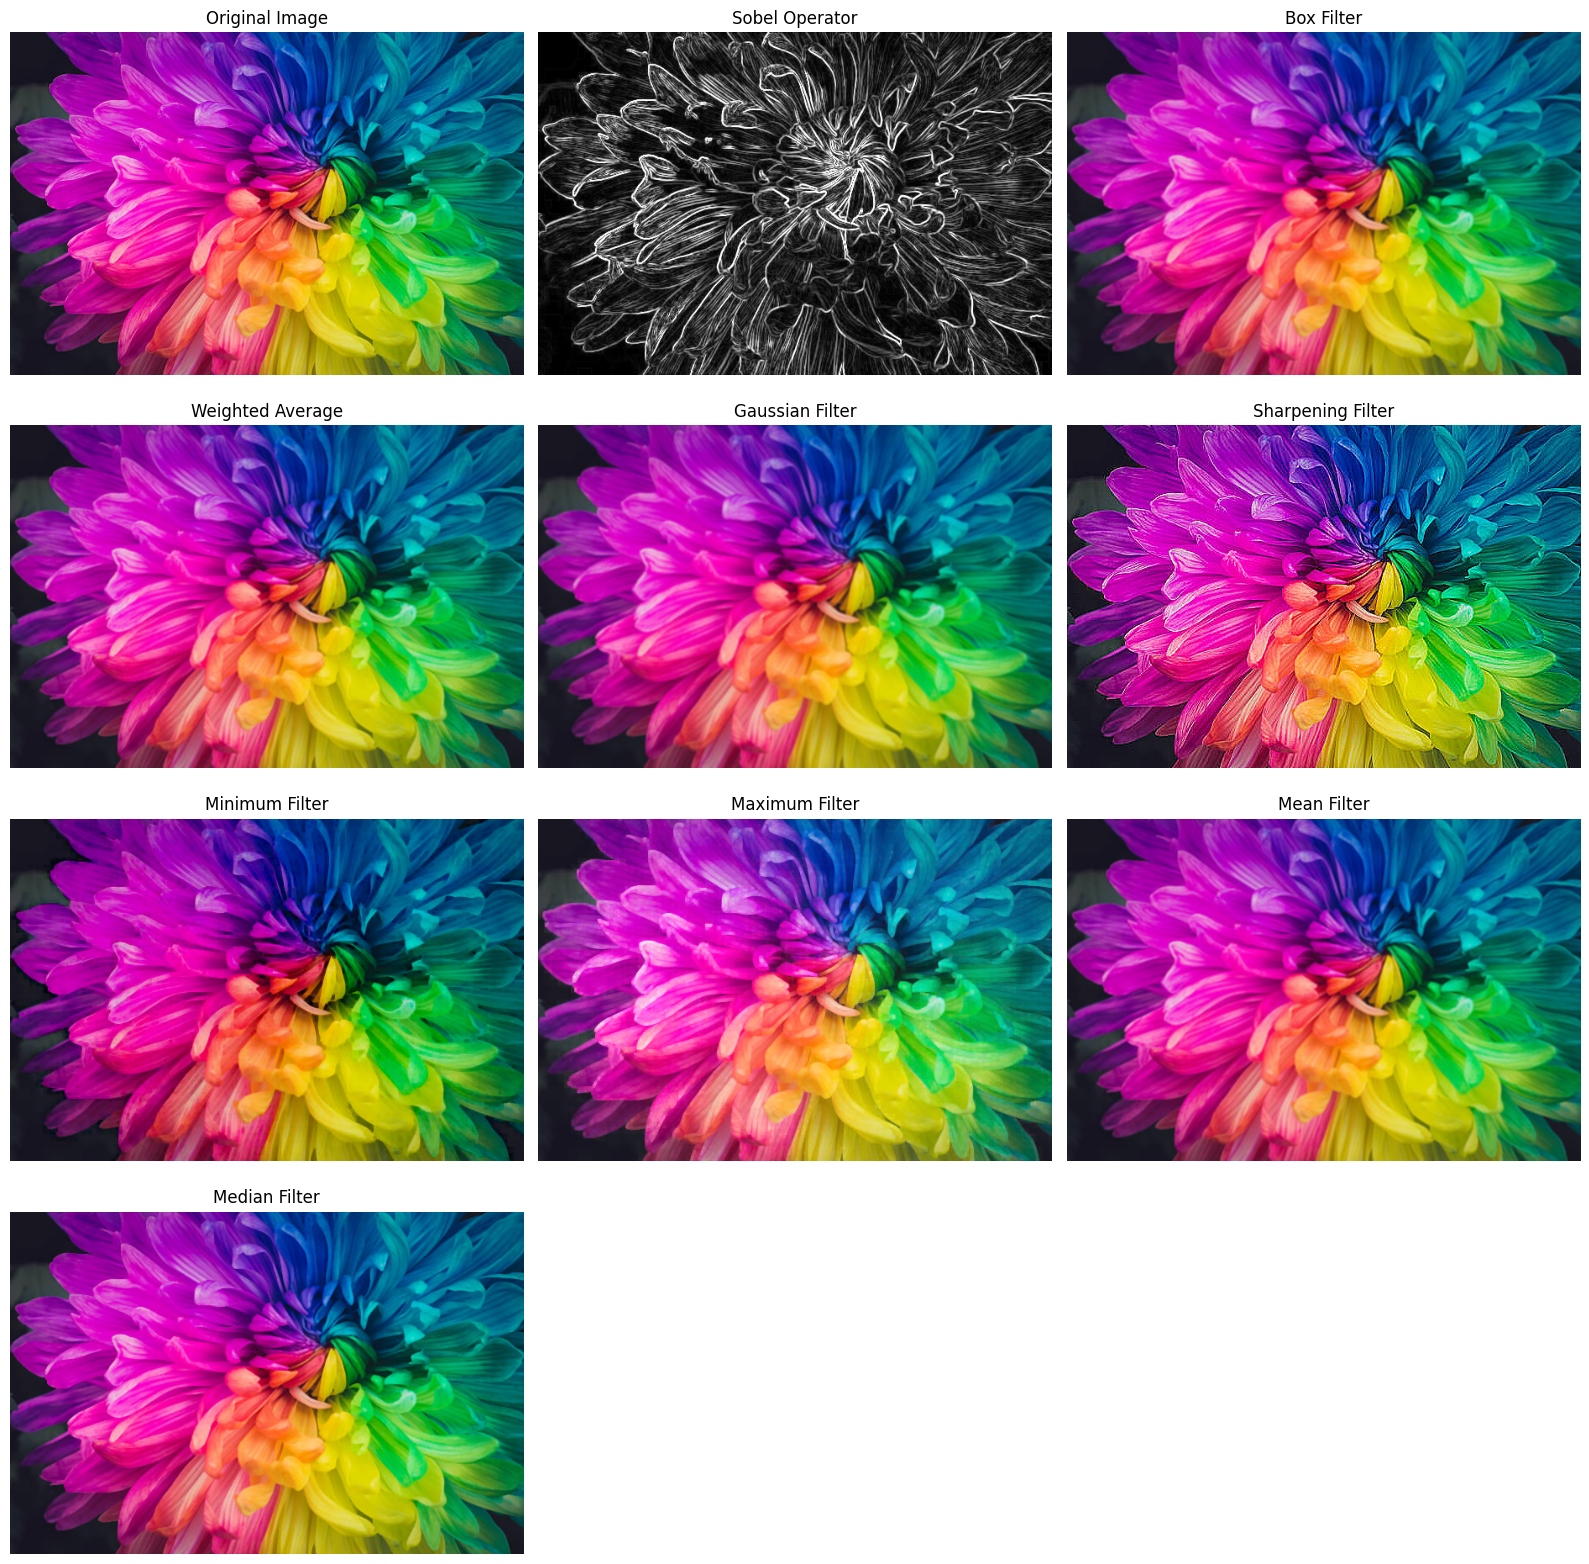

All Spatial Filters Applied Successfully!


In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

uploaded = files.upload()

image_name = list(uploaded.keys())[0]

img = cv2.imread(image_name)

if img is None:
    raise ValueError("Image could not be loaded!")

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

sobel_x = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)

sobel = cv2.magnitude(sobel_x, sobel_y)
sobel = cv2.convertScaleAbs(sobel)

box_filter = cv2.blur(img, (3, 3))

kernel = np.array([
    [1, 2, 1],
    [2, 4, 2],
    [1, 2, 1]
], dtype=np.float32) / 16

weighted_filter = cv2.filter2D(img, -1, kernel)

gaussian_filter = cv2.GaussianBlur(img, (5, 5), 0)

sharp_kernel = np.array([
    [0, -1, 0],
    [-1, 5, -1],
    [0, -1, 0]
])

sharpen_filter = cv2.filter2D(img, -1, sharp_kernel)

min_filter = cv2.erode(
    img, np.ones((3, 3), np.uint8)
)

max_filter = cv2.dilate(
    img, np.ones((3, 3), np.uint8)
)

mean_filter = cv2.blur(img, (3, 3))

median_filter = cv2.medianBlur(img, 3)

images = [
    ("Original Image", img),
    ("Sobel Operator", sobel),
    ("Box Filter", box_filter),
    ("Weighted Average", weighted_filter),
    ("Gaussian Filter", gaussian_filter),
    ("Sharpening Filter", sharpen_filter),
    ("Minimum Filter", min_filter),
    ("Maximum Filter", max_filter),
    ("Mean Filter", mean_filter),
    ("Median Filter", median_filter)
]

plt.figure(figsize=(16, 16))

for i, (title, image) in enumerate(images):
    plt.subplot(4, 3, i + 1)

    if len(image.shape) == 2:
        plt.imshow(image, cmap='gray')
    else:
        plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))

    plt.title(title)
    plt.axis('off')

plt.tight_layout()
plt.show()

cv2.imwrite("Sobel_Output.png", sobel)
cv2.imwrite("Box_Filter.png", box_filter)
cv2.imwrite("Weighted_Average.png", weighted_filter)
cv2.imwrite("Gaussian_Filter.png", gaussian_filter)
cv2.imwrite("Sharpening_Filter.png", sharpen_filter)
cv2.imwrite("Minimum_Filter.png", min_filter)
cv2.imwrite("Maximum_Filter.png", max_filter)
cv2.imwrite("Mean_Filter.png", mean_filter)
cv2.imwrite("Median_Filter.png", median_filter)

print("All Spatial Filters Applied Successfully!")
